<a href="https://colab.research.google.com/github/Aldyth11/Machine-Learning/blob/main/JS11/JS11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Klasifikasi SVM dengan Data Dummy Linier

### Langkah 1: Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### Langkah 2: Membuat Data Dummy

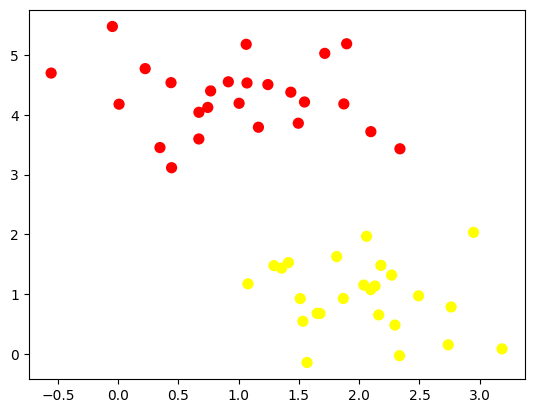

In [ ]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3: Membuat Ilustrasi Garis Pemisah

(-1.0, 3.5)

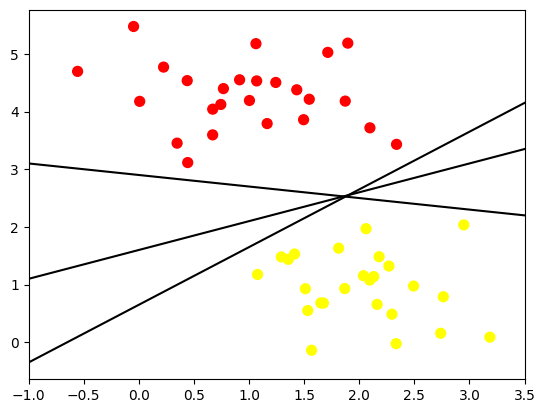

In [ ]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan beberapa garis pemisah potensial
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)

### Langkah 4: Ilustrasi Margin

(-1.0, 3.5)

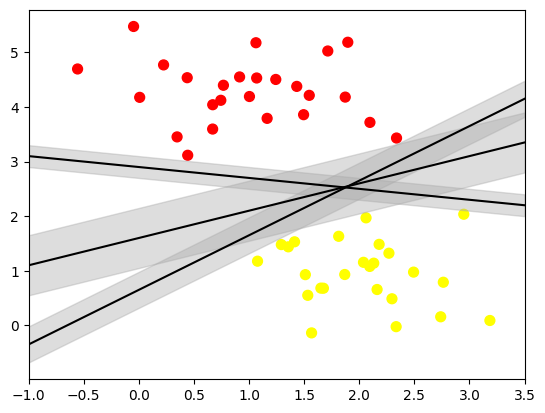

In [ ]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

### Langkah 5: Fitting Model SVM

In [ ]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

### Langkah 6: Membuat Fungsi Visualisasi Decision Function

In [ ]:
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 7: Plotting Fitting Model

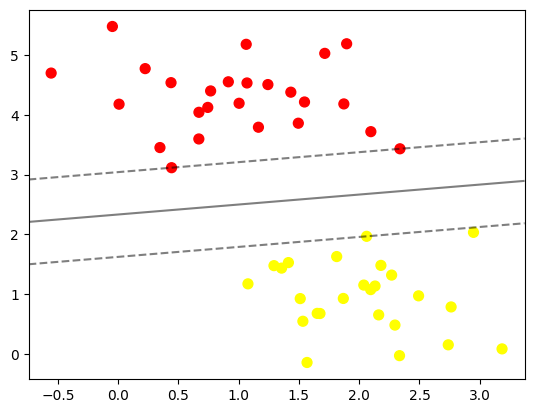

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

### Langkah 8: Menampilkan Support Vectors

In [ ]:
import pandas as pd
display(pd.DataFrame(model.support_vectors_, columns=['Feature 1', 'Feature 2']))

,Feature 1,Feature 2
0,0.443599,3.115309
1,2.338123,3.431168
2,2.061568,1.969186


### Langkah 9: Evaluasi Pengaruh Jumlah Data Terhadap Model

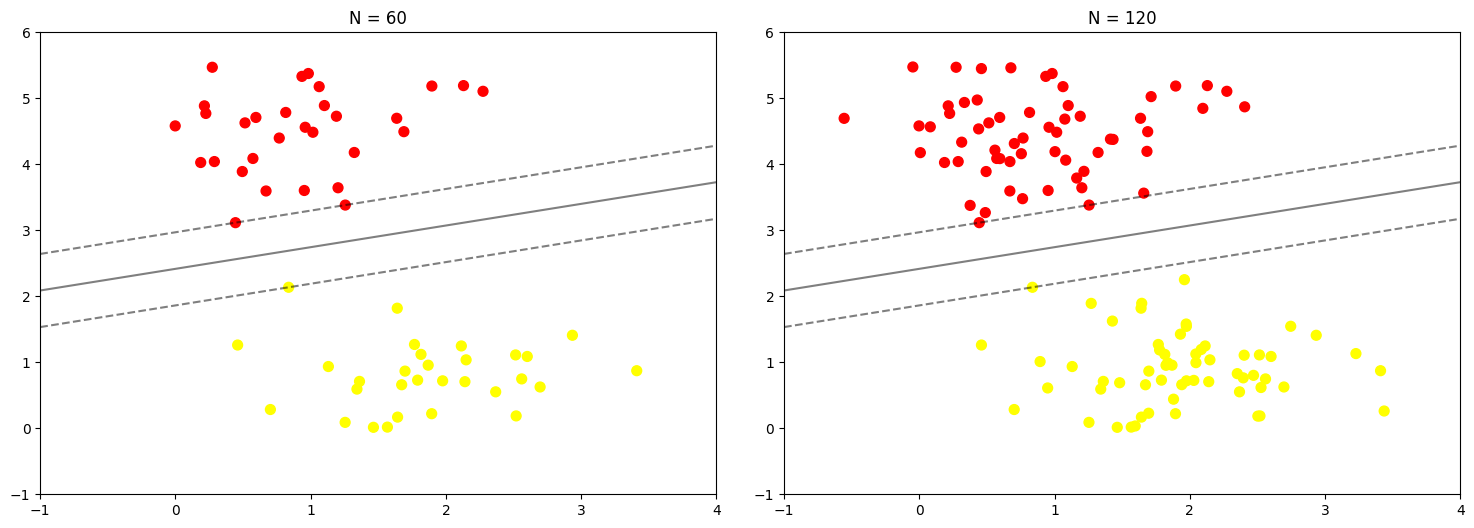

In [ ]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

### Langkah 10: Visualisasi Interaktif Menggunakan ipywidgets

In [ ]:
from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

# Praktikum 2: Klasifikasi SVM dengan Data Dummy Non-Linier

### Langkah 1a: Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

### Langkah 1b: Buat Kembali Fungsi Plotting

In [ ]:
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 1c: Buat Data Dummy Non-Linier

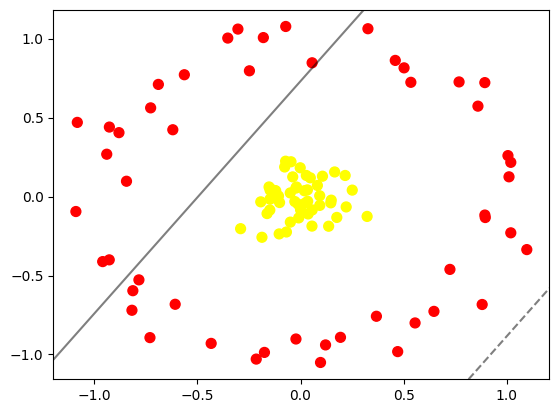

In [ ]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

### Langkah 1d: Visualisasi Proyeksi Radial 3D

In [ ]:
r = np.exp(-(X**2).sum(1))

from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-2.27165772e-02,  5.34808858e-02],
       [-2.90553716e-01, -2.03407847e-01],
       [ 1.36285436e-01, -1.87901441e-01],
       [ 3.32003144e-02,  4.22426696e-02],
       [-1.92781891e-01, -3.33849558e-02],
       [ 3.66050557e-02, -1.10111729e-01],
       [-7.83569686e-01, -5.27550448e-01],
       [ 2.16331016e-01,  1.33544646e-01],
       [-2.22100348e-02, -9.02013729e-01],
       [-1.18160404e-02, -4.83652052e-02],
       [-6.83705396e-02, -2.24360959e-01],
       [-4.98534565e-02,  2.29785511e-02],
       [ 1.48774630e-01, -2.28135480e-02],
       [-1.06916612e-01,  3.32552969e-03],
       [-9.26776726e-01,  4.40088329e-01],
       [ 9.69100873e-02, -1.05069024e+00],
       [-7.23551049e-02,  2.23874195e-01],
       [ 5.61338474e-02,  8.47094259e-01],
       [ 3.22781216e-01, -1.25804199e-01],
       [ 2.50695989e-01,  4.08155644e-02],
       [-4.94260673e-02, -1.61850427e-01],
       [ 4.71012964e-01, -9.81878982e-01],
       [-8.43804242e-01,  9.69587264e-02],
       [-1.03528823e-01, -2.36542078e-01],
       [-1.48949226e-01, -8.53451622e-02],
       [-6.07753010e-01, -6.82143377e-01],
       [ 8.93484007e-01,  7.21535644e-01],
       [ 7.68612277e-01,  7.25936252e-01],
       [-7.26686329e-01,  5.61676142e-01],
       [-4.33293209e-01, -9.29819913e-01],
       [-1.52585317e-01,  6.09049208e-02],
       [ 9.32429132e-02, -5.57937280e-02],
       [-2.76061282e-02, -3.16468407e-02],
       [-1.74990712e-01, -9.86938841e-01],
       [-1.62323110e-01, -1.07657427e-01],
       [-7.30044615e-01, -8.93299414e-01],
       [ 8.16125799e-02,  7.03556984e-02],
       [ 7.24274476e-01, -4.61244328e-01],
       [ 1.01070899e+00,  1.24969879e-01],
       [-1.20354567e-01,  3.68849308e-02],
       [-4.62664455e-02,  2.20303874e-01],
       [ 1.21270817e-01, -9.39510983e-01],
       [-2.47796008e-01,  7.96317434e-01],
       [ 1.46761972e-01, -3.97544248e-02],
       [-1.24247388e-01,  3.70364986e-02],
       [-9.39552372e-01,  2.68151818e-01],
       [-1.87058082e-01, -2.57825729e-01],
       [-1.35487842e-01,  4.22222620e-02],
       [-1.47462256e-01,  4.03713225e-02],
       [-8.17360306e-01, -7.20040756e-01],
       [-1.08911730e+00, -9.47716813e-02],
       [ 2.81303859e-02,  1.33508734e-01],
       [ 3.46654958e-02, -2.98950941e-02],
       [ 1.01938352e+00, -2.29644485e-01],
       [ 5.01947029e-01,  8.15033925e-01],
       [-6.89281846e-01,  7.10170671e-01],
       [ 8.80588129e-01, -6.83498196e-01],
       [-3.52725158e-01,  1.00359778e+00],
       [-9.59232616e-01, -4.11872004e-01],
       [-8.80301896e-01,  4.04735144e-01],
       [-3.03581484e-01,  1.06048495e+00],
       [-9.27447840e-01, -4.00807871e-01],
       [ 1.65345117e-01,  1.55781035e-01],
       [ 8.95655056e-01, -1.32784398e-01],
       [-7.17076007e-02,  1.07702456e+00],
       [ 1.06336966e-01,  1.28804446e-01],
       [ 6.46827430e-01, -7.27091144e-01],
       [ 5.54217673e-02, -1.87073769e-01],
       [ 1.75831700e-01, -1.32140418e-01],
       [-1.47829504e-01, -1.66742301e-02],
       [ 2.23513374e-02, -4.17961125e-02],
       [ 4.73214539e-02,  1.18698974e-01],
       [ 1.09699316e+00, -3.35841730e-01],
       [ 1.89492098e-02,  3.67885307e-02],
       [ 1.27785262e-04, -8.41488476e-02],
       [-1.80330617e-01,  1.00668929e+00],
       [-3.78122765e-02,  1.24562394e-01],
       [ 5.55317726e-01, -8.00344077e-01],
       [-1.08226432e+00,  4.69673906e-01],
       [-6.19260865e-01,  4.23060435e-01],
       [ 3.26734565e-01,  1.06273870e+00],
       [-1.94583417e-02,  6.02732507e-02],
       [ 3.67853436e-01, -7.58113090e-01],
       [-1.01654612e-01, -3.78599425e-02],
       [ 1.01936743e+00,  2.16723407e-01],
       [-8.79505742e-03, -1.35108990e-01],
       [ 1.93649514e-01, -8.91498399e-01],
       [ 8.60083912e-01,  5.72469908e-01],
       [ 4.59346489e-01,  8.62159320e-01],
       [ 5.34849237e-01,  7.23472797e-01],
       [-8.12992169e-01, -5.96189159e-01],
       [-5.63318228e-01,  7.71415747e-01

### Langkah 2a: Fitting Model dengan Kernel RBF

In [ ]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

### Langkah 2b: Plot Decision Boundaries Kernel RBF

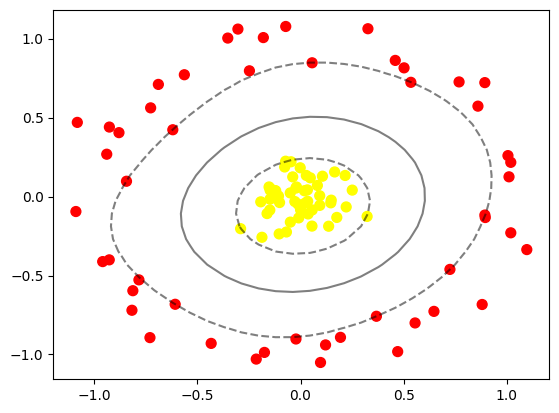

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

# Praktikum 3: SVM Data Overlapping

### Langkah 1: Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

### Langkah 2: Membuat Fungsi Plotting Decision Function

In [ ]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 3: Buat Data Dummy Overlapping

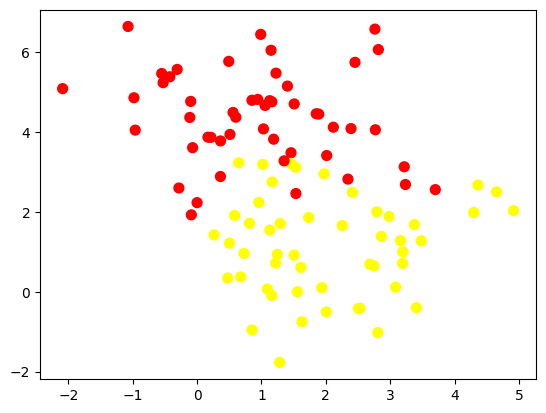

In [ ]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 4: Analisis Dampak Tuning Parameter C

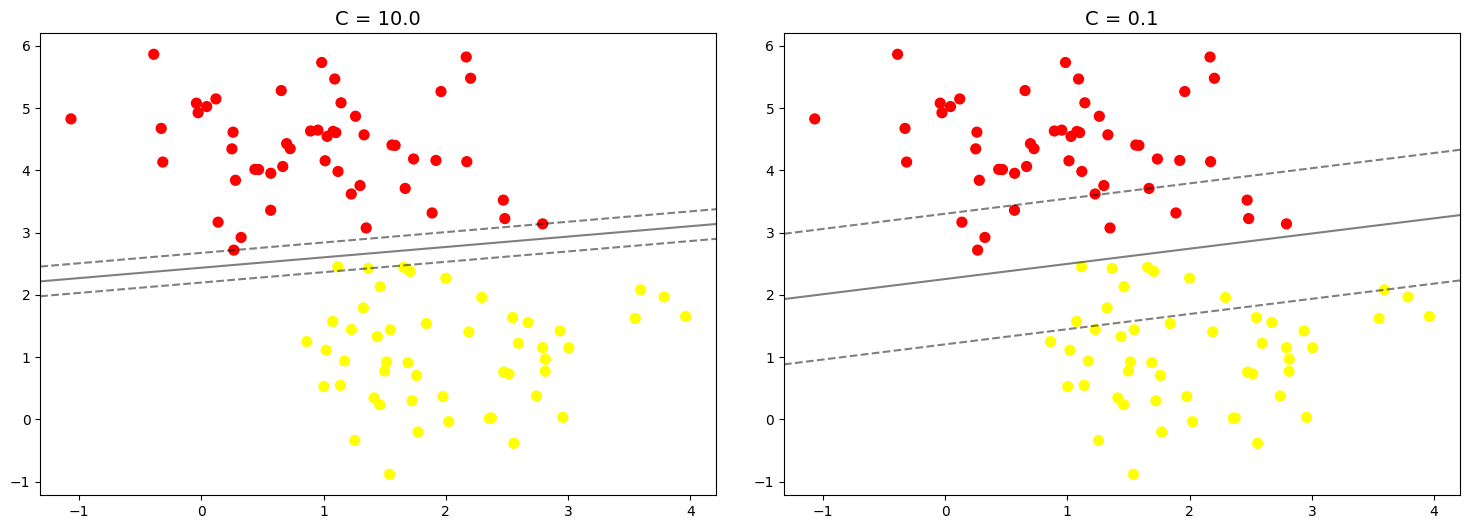

In [ ]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# Praktikum 4: Klasifikasi Citra Wajah

### Langkah 0: Unduh Dataset

In [ ]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### Langkah 1: Inspeksi Citra Wajah

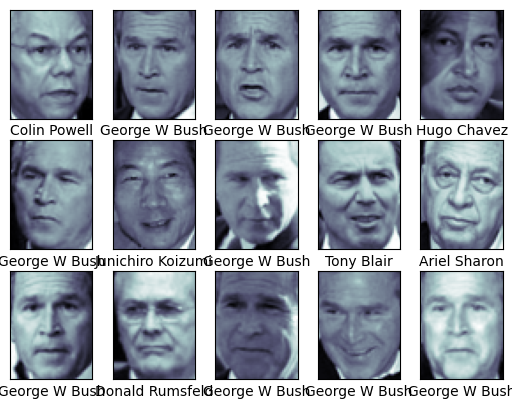

In [ ]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

### Langkah 2: Pra Pengolahan Data

In [23]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

### Langkah 3: Split Data

In [24]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

### Langkah 4a: Pembuatan Model dan Tuning Hyperparameter

In [25]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 6s, sys: 217 ms, total: 2min 6s
Wall time: 1min 26s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


### Langkah 4b: Prediksi Data Testing dengan Model Terbaik

In [26]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

### Langkah 5: Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

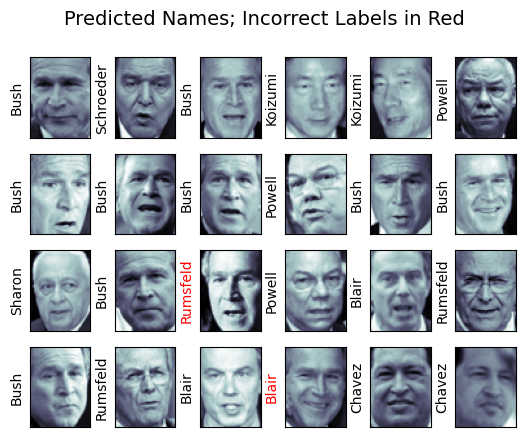

In [27]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                    color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

### Langkah 6a: Cek Performansi dengan Classification Report

In [28]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



### Langkah 6b: Visualisasi Confusion Matrix

Text(113.92222222222219, 0.5, 'predicted label')

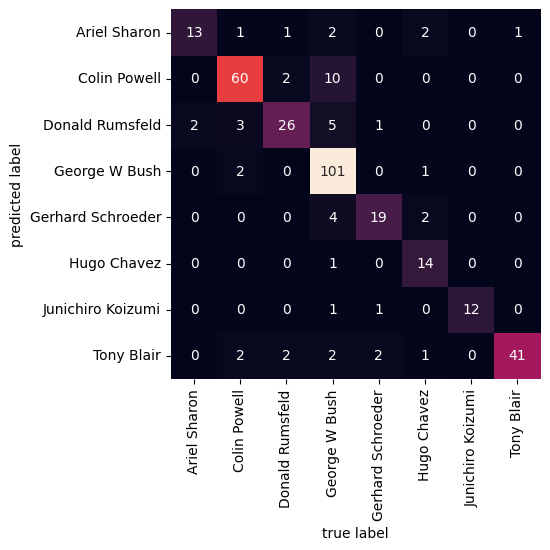

In [31]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

# Praktikum 5: Klasifikasi Citra Siang dan Malam

### Langkah 0: Import Library dan Unduh Dataset

In [32]:
# Unduh dan ekstrak dataset zip
import requests
import zipfile
import io

url = "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc"
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(url, headers=headers)

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(".")

# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

### Langkah 1: Load Data dan Visualisasikan

In [33]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

### Langkah 1b: Load Data Training

In [34]:
train_img = load_dataset(train_dir)

### Langkah 1c: Cek Data Pertama

In [35]:
train_img[0]

(array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[3, 3, 3],
         [3, 3, 3],
         [3, 3, 3],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[2, 2, 2],
         [2, 2, 2],
         [2, 2, 2],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]]], dtype=uint8),
 'night')

### Langkah 1d: Cek Ukuran Gambar Secara Acak

In [36]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 41
(700, 1280, 3)


### Langkah 1e: Buat Fungsi Visualisasi

In [37]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

### Langkah 1f: Tampilkan Gambar Acak

Shape	: (889, 1280, 3)
Label	: day


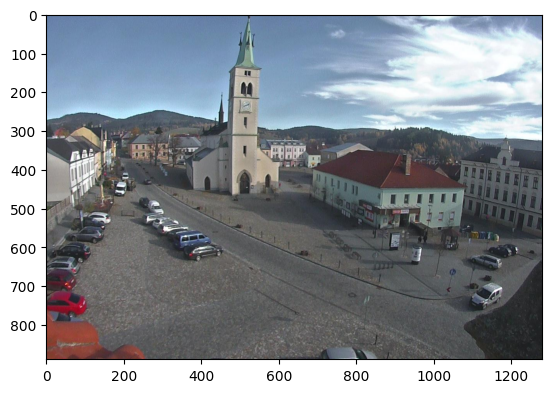

In [38]:
random_img_viz(train_img)

### Langkah 3: Pra Pengolahan Data

In [42]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

### Langkah 3b: Buat Fungsi Label Encoder

In [39]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

### Langkah 3c: Buat Fungsi Preprocess

In [40]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

### Langkah 3d: Eksekusi Preprocess Data Training

In [43]:
train_std_img_list = preprocess(train_img)

### Langkah 3e: Cek Ukuran Gambar Hasil Preprocess

In [44]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 181
(600, 1100, 3)


### Langkah 4: Ekstraksi Fitur (Average Brightness)

In [46]:
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

### Langkah 4b: Cek Fitur Kecerahan pada Gambar Acak

Image 204
Avg Brighness: 129.6682


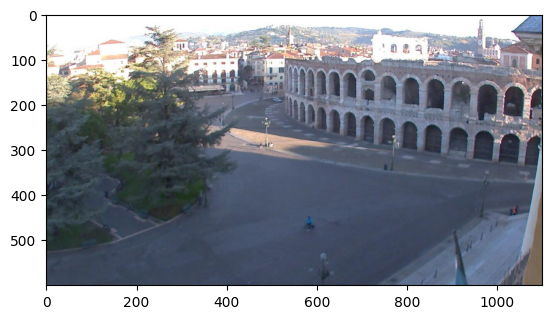

In [47]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

### Langkah 5: Klasifikasi dengan Metode Threshold

In [48]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

### Langkah 5b: Pengujian Prediksi Threshold Secara Acak

Image 118
Actual label: 0
Predicted label: 0


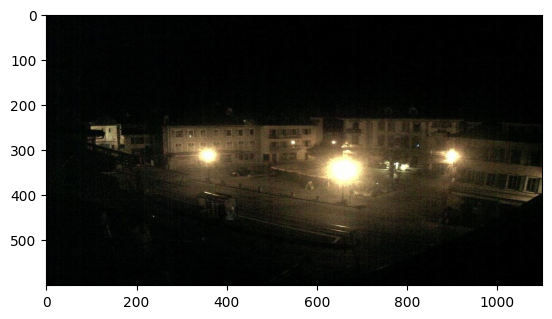

In [49]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

### Langkah 6: Evaluasi Manual

In [50]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

### Langkah 6b: Evaluasi Data Training

In [51]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


### Langkah 6c: Evaluasi Data Testing

In [52]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


### Langkah 4 Alternatif: Membuat Feature Vectors (SVM)

In [53]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

### Langkah 4 Alternatif b: Ekstraksi Fitur Data Training

In [54]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
display(train_avg_img.head())

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,13.262067,0.0
1,27.900359,0.0
2,8.305362,0.0
3,33.015533,0.0
4,27.820573,0.0


### Langkah 4 Alternatif c: Ekstraksi Fitur Data Testing

In [55]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
display(test_avg_img.head())

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,21.294233,0.0
1,26.130920,0.0
2,111.300176,0.0
3,12.978200,0.0
4,175.582911,0.0


### Langkah 5 Alternatif: Membuat Model SVM

In [56]:
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

### Langkah 6 Alternatif: Evaluasi Model SVM

In [57]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# Tugas Praktikum: Klasifikasi SVM pada Data Suara dan Citra

### Soal 1: Import Library

In [58]:
import io
import requests
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score

### Soal 1 - Langkah 1: Load Dataset voice.csv dari Link GitBook

In [59]:
url = "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2F4uIPAk2fE7hU8n1bM4kO%2Fvoice.csv?alt=media&token=3f846475-a72e-4ca2-bd03-24f2cbfca8c2"
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(url, headers=headers)

df_voice = pd.read_csv(io.StringIO(response.text))
display(df_voice.head())

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### Soal 1 - Langkah 2: Preprocessing dan Pemisahan Fitur & Target

In [60]:
X = df_voice.drop('label', axis=1)
y = df_voice['label']

le = LabelEncoder()
y = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

display(pd.DataFrame(X_scaled, columns=X.columns).head())

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
0,-4.049248,0.427355,-4.224901,-2.576102,-5.693607,-0.214778,2.293306,1.762946,-0.039083,0.471575,-2.141210,-4.049248,-1.812038,-1.097998,0.565959,-1.564205,-0.708404,-1.431422,-1.419137,-1.454772
1,-3.841053,0.611669,-3.999293,-2.486885,-5.588987,-0.258485,4.548056,4.433008,-0.065236,0.594431,-2.141210,-3.841053,-1.079594,-1.091533,-0.294030,-1.561916,-0.708404,-1.418107,-1.405818,-1.014103
2,-3.463066,1.603848,-4.095851,-2.706986,-3.928699,0.909326,6.513656,7.326207,-1.083730,0.398261,-2.141210,-3.463066,-1.365368,-1.100397,0.410480,-1.563866,-0.708404,-1.429203,-1.416917,-1.065344
3,-0.992157,0.899998,-0.759454,-0.901418,-0.711205,0.632690,-0.449858,-0.240099,1.516383,1.797340,-1.054576,-0.992157,-1.666966,-0.988934,-0.294030,-1.195367,-0.708404,-1.273867,-1.261532,0.614286
4,-1.530640,1.322561,-1.676948,-1.268395,-0.792029,1.005588,-0.480911,-0.238940,1.708336,2.114740,-0.790514,-1.530640,-1.127233,-1.034015,0.260185,-0.221660,-0.708404,0.124154,0.136933,0.289046


### Soal 1 - Langkah 3: Evaluasi Model SVM dengan Berbagai Kernel dan Split Ratio

In [61]:
kernels = ['linear', 'poly', 'rbf']
ratios = [0.3, 0.2]
results = []

for test_size in ratios:
    train_ratio = int((1 - test_size) * 100)
    test_ratio = int(test_size * 100)
    split_label = f"{train_ratio}:{test_ratio}"

    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=test_size, random_state=42
    )

    for kernel in kernels:
        model = SVC(kernel=kernel)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        results.append({
            'Split Ratio': split_label,
            'Kernel': kernel,
            'Accuracy': acc
        })

df_results = pd.DataFrame(results)
display(df_results)

,Split Ratio,Kernel,Accuracy
0,70:30,linear,0.970557
1,70:30,poly,0.956887
2,70:30,rbf,0.981073
3,80:20,linear,0.976341
4,80:20,poly,0.968454
5,80:20,rbf,0.982650


### Soal 1 - Langkah 4: Tabulasi Hasil Perfomansi SVM

In [62]:
df_pivot = df_results.pivot(index='Kernel', columns='Split Ratio', values='Accuracy')
display(df_pivot)

Split Ratio,70:30,80:20
Kernel,,
linear,0.970557,0.976341
poly,0.956887,0.968454
rbf,0.981073,0.982650


### Soal 2: Import Library dan Unduh Dataset Citra Siang/Malam

In [63]:
import zipfile
import cv2
import matplotlib.image as mpimg
from pathlib import Path

url_zip = "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc"
response = requests.get(url_zip, headers={'User-Agent': 'Mozilla/5.0'})

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(".")

train_dir = "images/training/"
test_dir = "images/test/"

### Soal 2 - Langkah 1: Fungsi Load dan Preprocess Data Citra

In [64]:
def load_all_images():
    all_imgs = []
    for dir_path in [train_dir, test_dir]:
        p = Path(dir_path)
        for folder in p.glob('*'):
            label_str = str(folder).split('/')[-1]
            label_num = 1 if label_str == 'day' else 0
            for file in folder.glob('*.jpg'):
                img = mpimg.imread(file)
                if img is not None:
                    std_img = cv2.resize(img, (1100, 600))
                    all_imgs.append((std_img, label_num))
    return all_imgs

all_image_data = load_all_images()
print(f"Total dataset citra: {len(all_image_data)}")

Total dataset citra: 400


### Soal 2 - Langkah 2: Ekstraksi Fitur Histogram Warna

In [65]:
def extract_histogram_features(img_list):
    features = []
    labels = []
    for img, label in img_list:
        hist_b = cv2.calcHist([img], [0], None, [32], [0, 256])
        hist_g = cv2.calcHist([img], [1], None, [32], [0, 256])
        hist_r = cv2.calcHist([img], [2], None, [32], [0, 256])

        hist_feat = np.concatenate([hist_b, hist_g, hist_r]).flatten()
        hist_feat = hist_feat / np.sum(hist_feat)

        features.append(hist_feat)
        labels.append(label)

    return np.array(features), np.array(labels)

X_img, y_img = extract_histogram_features(all_image_data)
display(pd.DataFrame(X_img).head())

,0,1,2,3,4,5,6,7,8,9,...,86,87,88,89,90,91,92,93,94,95
0,0.249621,0.026674,0.016606,0.010823,0.006313,0.003559,0.002492,0.001965,0.001509,0.001372,...,0.000320,0.000306,0.000304,0.000269,0.000280,0.000248,0.000234,0.000291,0.000377,0.001497
1,0.008156,0.076400,0.132104,0.062470,0.016505,0.006658,0.004094,0.003187,0.002589,0.002488,...,0.000046,0.000048,0.000053,0.000054,0.000061,0.000061,0.000075,0.000060,0.000032,0.000019
2,0.285433,0.023136,0.006510,0.003896,0.002832,0.001877,0.001338,0.001255,0.001224,0.000992,...,0.000181,0.000175,0.000180,0.000188,0.000156,0.000159,0.000176,0.000212,0.000272,0.001165
3,0.003233,0.036415,0.090574,0.105090,0.053952,0.011134,0.004458,0.003369,0.002628,0.002179,...,0.000039,0.000041,0.000031,0.000049,0.000053,0.000057,0.000053,0.000051,0.000035,0.000017
4,0.007923,0.101996,0.132060,0.042643,0.012577,0.005501,0.003757,0.002975,0.002487,0.002069,...,0.000029,0.000033,0.000035,0.000033,0.000040,0.000038,0.000031,0.000035,0.000029,0.000012


### Soal 2 - Langkah 3: Train-Test Split 80:20

In [66]:
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_img, y_img, test_size=0.2, random_state=42, stratify=y_img
)

### Soal 2 - Langkah 4: Training dan Hyperparameter Tuning SVM Kernel RBF

In [67]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy'
)
grid_search.fit(X_train_img, y_train_img)

best_svm = grid_search.best_estimator_
y_pred_img = best_svm.predict(X_test_img)
acc_test_img = accuracy_score(y_test_img, y_pred_img)

df_image_eval = pd.DataFrame([{
    'Best C': grid_search.best_params_['C'],
    'Best Gamma': grid_search.best_params_['gamma'],
    'Train Accuracy (Best CV)': grid_search.best_score_,
    'Test Accuracy': acc_test_img
}])

display(df_image_eval)

,Best C,Best Gamma,Train Accuracy (Best CV),Test Accuracy
0,10,scale,0.996875,1.0
